In [1]:
import zipfile
import tensorflow as tf
# unzip the downloaded file
zip_ref = zipfile.ZipFile("pizza_steak.zip")
zip_ref.extractall()
zip_ref.close()

In [2]:
!dir pizza_steak

 Volume in drive C is Windows
 Volume Serial Number is 98FA-EFFA

 Directory of C:\Users\shali\NEW PROJECT FOR INDEED AND RESUME\pizza_steak

09/29/2026  11:35 AM    <DIR>          .
11/07/2026  03:58 PM    <DIR>          ..
09/29/2026  11:35 AM    <DIR>          test
09/29/2026  11:35 AM    <DIR>          train
               0 File(s)              0 bytes
               4 Dir(s)  317,821,169,664 bytes free


In [3]:
!dir pizza_steak\train\steak\

 Volume in drive C is Windows
 Volume Serial Number is 98FA-EFFA

 Directory of C:\Users\shali\NEW PROJECT FOR INDEED AND RESUME\pizza_steak\train\steak

09/29/2026  11:35 AM    <DIR>          .
09/29/2026  11:35 AM    <DIR>          ..
11/07/2026  03:59 PM            36,185 1000205.jpg
11/07/2026  03:59 PM            34,497 100135.jpg
11/07/2026  03:59 PM           116,802 101312.jpg
11/07/2026  03:59 PM            56,754 1021458.jpg
11/07/2026  03:59 PM            34,143 1032846.jpg
11/07/2026  03:59 PM            24,688 10380.jpg
11/07/2026  03:59 PM            37,134 1049459.jpg
11/07/2026  03:59 PM            49,841 1053665.jpg
11/07/2026  03:59 PM            59,983 1068516.jpg
11/07/2026  03:59 PM            28,996 1068975.jpg
11/07/2026  03:59 PM            29,525 1081258.jpg
11/07/2026  03:59 PM            49,577 1090122.jpg
11/07/2026  03:59 PM            59,976 1093966.jpg
11/07/2026  03:59 PM            60,253 1098844.jpg
11/07/2026  03:59 PM            69,843 1100074.jpg
11

In [4]:
import os
# walk through pizza_steak and list the no. of files
for dirpath, dirnames, filenames in os. walk("pizza_steak"):
    print(f"there are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}',")



there are 2 directories and 0 images in 'pizza_steak',
there are 2 directories and 0 images in 'pizza_steak\test',
there are 0 directories and 250 images in 'pizza_steak\test\pizza',
there are 0 directories and 250 images in 'pizza_steak\test\steak',
there are 2 directories and 0 images in 'pizza_steak\train',
there are 0 directories and 750 images in 'pizza_steak\train\pizza',
there are 0 directories and 750 images in 'pizza_steak\train\steak',


In [5]:
# get the classnames programmactically
import pathlib
import numpy as np
data_dir = pathlib.Path("pizza_steak/train")
class_names = np.array(sorted([item.name for item in data_dir.glob("*")])) #  created a list of classnames from the subdirector
print(class_names)

['pizza' 'steak']


## 1. visualize data


In [7]:
# let's visualize our images
import matplotlib.pyplot as plt # to view images
import matplotlib.image as mpimg
import random

def view_random_image(target_dir, target_class):
  # setup the target directory (we'll view images from here)
  target_folder = target_dir+target_class

  # get a random image path
  random_image  = random.sample(os.listdir(target_folder),1)
  print(random_image)

  #read in the image and plot it using matplotlib
  img = mpimg.imread(target_folder + "/" + random_image[0] )
  plt.imshow(img)
  plt.title(target_class)
  plt.axis("off");

  print(f"image shape: {img.shape}") # show the shape of the image

  return img



['667075.jpg']
image shape: (384, 512, 3)
['403431.jpg']
image shape: (512, 512, 3)


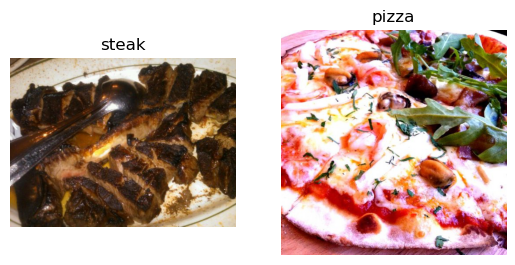

In [8]:

plt.figure()
plt.subplot(1,2,1)
steak_img = view_random_image("pizza_steak/train/","steak")
plt.subplot(1,2,2)
pizza_img = view_random_image("pizza_steak/train/","pizza")


## 2.preprocess the data(prepare it for a model)


In [10]:
# define directory dataset paths
train_dir = "pizza_steak/train/"
test_dir= "pizza_steak/test/"


In [11]:
# create train and test data generators and rescale the data
from tensorflow.keras.preprocessing.image import ImageDataGenerator
train_datagen = ImageDataGenerator(rescale=1/225.)
test_datagen = ImageDataGenerator(rescale=1/225.)


In [12]:
# load in our image data from directories and turn them into batches
train_data = train_datagen.flow_from_directory(directory=train_dir, # target directory of images
                                               target_size=(224,224), # Target size of images (height, width)
                                               class_mode="binary", # type of data you're working with
                                               batch_size=32) # size of minibatches to load data into

test_data = test_datagen.flow_from_directory(directory=test_dir,
                                             target_size=(224,224),
                                               class_mode="binary",
                                               batch_size=32)

Found 1500 images belonging to 2 classes.
Found 500 images belonging to 2 classes.


In [13]:
# get a sample of a train data batch
images, labels = next(train_data)  # get the "next" batch of images/labels in train_data
len(images), len(labels)

(32, 32)

In [14]:
# how many batches are there ?
len(train_data)


47

In [15]:
1500/32

46.875

In [16]:
# get the first two images
images[:2], images[0].shape

(array([[[[0.8977778 , 0.52000004, 0.3377778 ],
          [0.94222224, 0.5644445 , 0.4       ],
          [0.9466667 , 0.5644445 , 0.41777778],
          ...,
          [0.7822223 , 0.5555556 , 0.31111112],
          [0.76      , 0.53333336, 0.29777777],
          [0.7111111 , 0.47555557, 0.24444444]],
 
         [[0.93333334, 0.52444446, 0.3511111 ],
          [0.96888894, 0.5555556 , 0.40444446],
          [0.99111116, 0.5777778 , 0.44      ],
          ...,
          [0.7733334 , 0.5466667 , 0.30222222],
          [0.74222225, 0.51555556, 0.28      ],
          [0.6888889 , 0.46222222, 0.22666667]],
 
         [[0.92444444, 0.4977778 , 0.32      ],
          [0.96888894, 0.5377778 , 0.38222224],
          [0.96444446, 0.5288889 , 0.4       ],
          ...,
          [0.7822223 , 0.5644445 , 0.31555557],
          [0.75555557, 0.5377778 , 0.2888889 ],
          [0.6977778 , 0.47555557, 0.24000001]],
 
         ...,
 
         [[0.88      , 0.64      , 0.37333333],
          [0.87111

In [17]:
# view the first batch of labels
labels

array([0., 1., 1., 1., 0., 1., 0., 1., 0., 0., 0., 1., 1., 1., 1., 1., 1.,
       0., 1., 0., 1., 0., 0., 1., 0., 1., 0., 1., 1., 1., 1., 0.],
      dtype=float32)

## 3. Create a CNN model (start with a baseline)

A baseline is a relatively simple model or existing result that you setup when beginning a machine learning experiment and then as you keep experimenting, you try to beat the baseline.

how to know what archieture to use?
note: in deep learning, there is almost an infinite amount of architectures you could create. so one of the best ways to get started is to start with something simple and see if it works on you data then introduce complexity as required (e.g look at which current model is performing best in the field for you problem


In [19]:
# make the creating of our model a little easier
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPool2D, Activation
from tensorflow.keras import Sequential


In [20]:
# plot the validation and training curves seperately
def plot_loss_curves(history):
    """
    Returns seperate loss curves for training and validation metrics.
    """
    loss = history.history["loss"]
    val_loss = history.history["val_loss"]

    accuracy = history.history["accuracy"]
    val_accuracy = history.history["val_accuracy"]

    epochs = range(len(history.history["loss"])) # how many epochs did we run for?
    

    #plot loss
    plt.plot(epochs, loss, label="training_loss")
    plt.plot(epochs,val_loss,label="val_loss")
    plt.title("loss")
    plt.xlabel("epoch")
    plt.legend()

    #plot accuracy
    plt.figure()
    plt.plot(epochs, accuracy, label="training_accuracy")
    plt.plot(epochs,val_accuracy,label="val_accuracy")
    plt.title("accuracy")
    plt.xlabel("epoch")
    plt.legend();


In [21]:
# create imageDataGenerator training instance with data augmentation
# we can reduce overfitting with data augmentation
train_datagen_augmented = ImageDataGenerator(rescale=1/255.,
                                             rotation_range=0.2, #how much do you want to rotate an image
                                             shear_range=0.2, # how much do you wnat to shear an image
                                             zoom_range=0.2,# zoom in randomly on an image
                                             width_shift_range=0.2, # move your image around on the x-axis
                                             height_shift_range=0.2, # move your image around on the y-axis
                                             horizontal_flip=True) # do you want to flip an image?

# create ImageDataGenerator without data augmentation
train_datagen = ImageDataGenerator(rescale=1/255.)
# create ImageDataGenerator without data augmentation for the test dataset
test_datagen = ImageDataGenerator(rescale=1/255.)


In [22]:
# import data and augment it and shuffle from training directory
train_data_augmented_shuffled = train_datagen_augmented.flow_from_directory(train_dir,
                                                                            target_size=(224,224),
                                                                            class_mode="binary",
                                                                            batch_size=32,
                                                                            shuffle=True) # shuffle data this time



Found 1500 images belonging to 2 classes.


In [23]:
# get sample data batches
images, labels = next(train_data)
augmented_images, augmented_labels = next(train_data_augmented_shuffled)# labels are augmented .. only data (images)



In [78]:
model_8 = tf.keras.Sequential([
    # Block 1
    tf.keras.layers.Conv2D(32, (3,3), activation="relu", input_shape=(224, 224, 3)),
    tf.keras.layers.MaxPooling2D(2,2),

    # Block 2
    tf.keras.layers.Conv2D(64, (3,3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2,2),

    # Block 3
    tf.keras.layers.Conv2D(128, (3,3), activation="relu"),
    tf.keras.layers.MaxPooling2D(2,2),

    # Flatten and classify
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation="sigmoid")  
])

# compile the model
model_8.compile(
    loss="binary_crossentropy",  
    optimizer="Adam",
    metrics=["accuracy"]
)

# fit the model
history_8 = model_8.fit(
    train_data_augmented_shuffled,
    epochs=5,
    steps_per_epoch=len(train_data_augmented_shuffled),
    validation_data=test_data,
    validation_steps=len(test_data)
)

Epoch 1/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 47s 956ms/step - accuracy: 0.6113 - loss: 0.8779 - val_accuracy: 0.6540 - val_loss: 0.5812
Epoch 2/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 49s 1s/step - accuracy: 0.7353 - loss: 0.5485 - val_accuracy: 0.8480 - val_loss: 0.3827
Epoch 3/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 52s 1s/step - accuracy: 0.7700 - loss: 0.4892 - val_accuracy: 0.8480 - val_loss: 0.3465
Epoch 4/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.7933 - loss: 0.4475 - val_accuracy: 0.8680 - val_loss: 0.2932
Epoch 5/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 58s 1s/step - accuracy: 0.8107 - loss: 0.4296 - val_accuracy: 0.8420 - val_loss: 0.3497


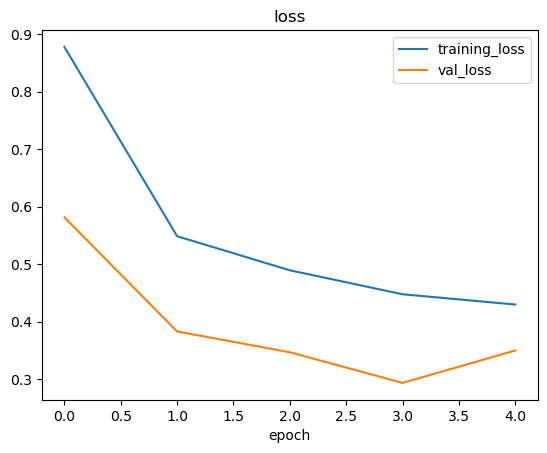

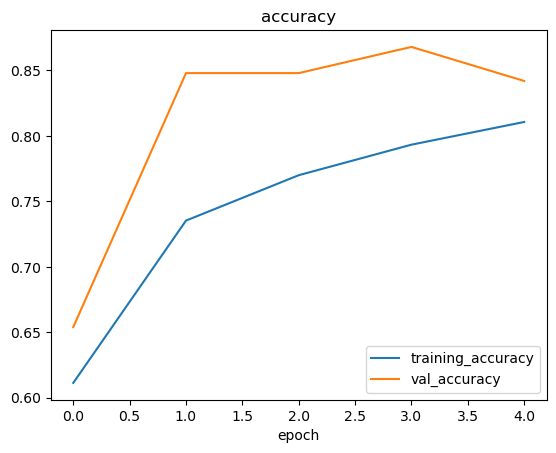

In [79]:
# plot loss curves
plot_loss_curves(history_8)

(-0.5, 987.5, 974.5, -0.5)

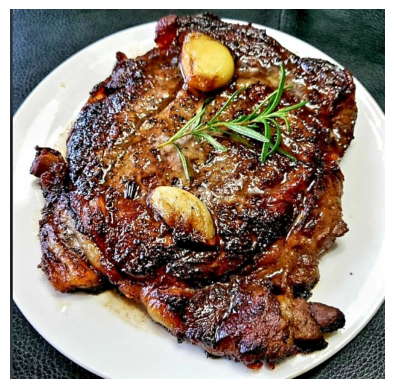

In [80]:
# View our example image
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import requests

steak = mpimg.imread(r"C:\Users\shali\OneDrive\Pictures\steak01.png")
plt.imshow(steak)
plt.axis(False)



This is the steak image we loaded. now we have to put this image in the model and make the model predict if this is steak or not

In [82]:
steak.shape

(975, 988, 3)

In [83]:
# create a function to import and image and resize it to bew able to be used with our model
def load_and_prep_image(filename, img_shape=224):
    """
    Reads and image from filename, turns it into a tensor and reshape it 
    to (img_shape, img_shape, colour_channels).
    """
    # read in the iamge
    img = tf.io.read_file(filename)
    #decode the read file into a tensor
    img = tf.image.decode_image(img)
    # resize the image
    img = tf.image.resize(img, size=[img_shape, img_shape])
    # rescale the image (get all values between 0 and 1)
    img = img/255.
    return img
    

In [84]:
# load in and preprocess our custom image
steak = load_and_prep_image(r"C:\Users\shali\OneDrive\Pictures\steak01.png")

In [85]:
steak

<tf.Tensor: shape=(224, 224, 3), dtype=float32, numpy=
array([[[0.19215687, 0.21176471, 0.23529412],
        [0.18364842, 0.22832629, 0.2803921 ],
        [0.3850908 , 0.49097314, 0.6067645 ],
        ...,
        [0.04497702, 0.15085937, 0.11927667],
        [0.19374333, 0.2996257 , 0.28001782],
        [0.09218067, 0.19529682, 0.16000271]],

       [[0.19215687, 0.21176471, 0.23529412],
        [0.18359558, 0.22827347, 0.28033927],
        [0.3399099 , 0.44579226, 0.5615836 ],
        ...,
        [0.        , 0.10170288, 0.0742519 ],
        [0.12623921, 0.23212156, 0.20467058],
        [0.17668496, 0.2798011 , 0.24450698]],

       [[0.18939076, 0.2089986 , 0.23252802],
        [0.18393119, 0.22860906, 0.28067487],
        [0.3484083 , 0.45429066, 0.57008195],
        ...,
        [0.19919029, 0.30507264, 0.2817534 ],
        [0.19416115, 0.3000435 , 0.2725925 ],
        [0.00285745, 0.09016505, 0.05487094]],

       ...,

       [[0.23308295, 0.24484766, 0.27229866],
        [0.22

In [86]:
expanded_steak = tf.expand_dims(steak, axis=0)

In [87]:
pred=model_7.predict(tf.expand_dims(steak, axis=0))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


In [88]:
# remind ourselves of our class names 
class_names

array(['pizza', 'steak'], dtype='<U5')

In [89]:
# we can index the predicted class by rounding the prediction probability and indexing it on the class name
pred_class = class_names[int(tf.round(pred))]
pred_class


'steak'

In [90]:
def pred_and_plot(model, filename, class_names=class_names):
    """
    import an image located at filename, makes a prediction with model and plots the image with the predicted class as the title.
    """
    # import the target image and preprocess it
    img= load_and_prep_image(filename)

    #make a prediction
    pred = model.predict(tf.expand_dims(img, axis=0))

    # get the predicted class
    pred_class= class_names[int(tf.round(pred))]

    #plot the image and predicted class
    plt.imshow(img)
    plt.title(f"prediction:{pred_class}")
    plt.axis(False);
    

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step


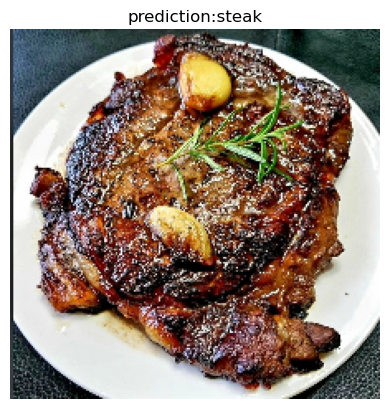

In [91]:
# test our model on a custom image
pred_and_plot(model_8, r"C:\Users\shali\OneDrive\Pictures\steak01.png")

trying another image

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step


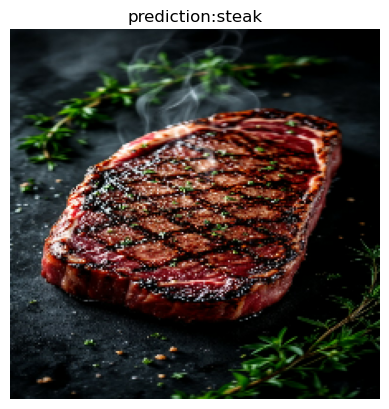

In [93]:
steak = mpimg.imread(r"C:\Users\shali\OneDrive\Pictures\steak02.jpg")
plt.imshow(steak)
plt.axis(False)

pred_and_plot(model_8, r"C:\Users\shali\OneDrive\Pictures\steak02.jpg")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


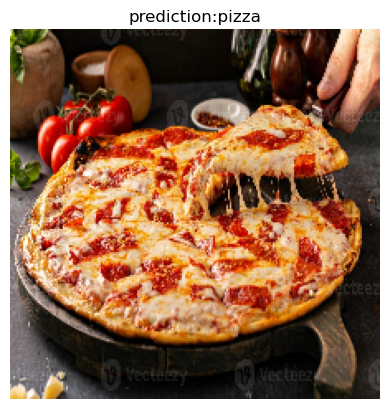

In [94]:
pizza = mpimg.imread(r"C:\Users\shali\OneDrive\Pictures\pizza02.jpg")
plt.imshow(pizza)
plt.axis(False)

pred_and_plot(model_8, r"C:\Users\shali\OneDrive\Pictures\pizza02.jpg")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step


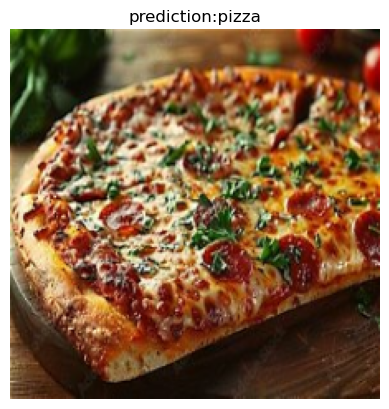

In [95]:
pizza = mpimg.imread(r"C:\Users\shali\OneDrive\Pictures\pizza03.jpg")
plt.imshow(pizza)
plt.axis(False)

pred_and_plot(model_8, r"C:\Users\shali\OneDrive\Pictures\pizza03.jpg")